# Experimento 006 — stacking sin fuga indirecta y simplificación

Ejecutar desde raíz: `.venv/bin/python -m src.experimento_006` para reproducir entrenamiento, y `.venv/bin/python src/informe_006.py` para regenerar este notebook. Guardar copias si se necesita preservar otra ejecución de 006. No se modifican versiones anteriores.

La justificación detallada está en `reports/revision_recomendaciones_006.md`. El documento del auditor se trata como recomendaciones, no como prueba de resultados cuya ejecución no está disponible.

In [1]:
from pathlib import Path
import os,json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
if not Path('reports/registro_006.json').exists():os.chdir('..')
r=json.loads(Path('reports/registro_006.json').read_text())
display(Markdown(Path('reports/resumen_006.md').read_text()))
cv=pd.read_csv('reports/resultados_cv_006.csv')
display(cv[['name','mean_train_score','mean_test_score','std_test_score','f1_gap','selected']])
display(pd.read_csv('reports/cv_006_anidada.csv'))
display(pd.DataFrame(r['per_class']).T)

# Versión 006: recomendaciones contrastadas

Candidato seleccionado: **stack_svc_lr_nb**.

| F1 macro | Referencia 005 | Procedimiento 006 |
|---|---:|---:|
| Selección CV | 0.874163 | 0.878010 |
| Brecha entrenamiento-CV | 0.125293 | 0.121140 |
| Predicciones OOF externas agrupadas | 0.873382 | 0.878421 |

F1 entrenamiento de selección: 0.999150. Media de folds externos: 0.878413 ± 0.004300. El F1 sobre todas las predicciones externas no es la misma operación que promediar F1 por fold.

## Cambios y evaluación

Se contrastaron referencia 005, C=1/min_df=5, eliminación de interacciones de epílogo y stacking SVC/LR/NB. Solo F1 macro dirige la selección, con regla previa de control de brecha y mejora mínima. Los detalles se fijaron en reports/plan_006.json y src/modelos_006.py.

La CV externa repite selección interna. Cada stacking genera sus propios scores OOF de bases dentro del entrenamiento recibido; no reutiliza scores globales para entrenar el agregador. QuantileTransformer aprende únicamente sobre OOF de entrenamiento, nunca calcula rangos a partir del lote eval. Las bases no necesitan ser estadísticamente independientes: su utilidad debe comprobarse fuera de entrenamiento.

La cifra exploratoria 0,8805 del documento del auditor no se usa como resultado verificado: no se encontró su implementación y artefactos intermedios en las carpetas revisadas. Esta implementación tampoco pretende reproducir exactamente un ranking por fold no especificado.

El público 005 aportado por el usuario es 0,88111; no se consultó la plataforma. El público 006 es desconocido. Meta local 0,90: no alcanzada en esta OOF. No se extrapola del score público anterior.

## Sobreajuste y límites

La brecha reportada es diagnóstica; su reducción no demuestra ausencia de sobreajuste. El mismo desarrollo se ha explorado en varias versiones. La CV anidada protege los ajustes de esta ronda, pero no borra adaptación histórica ni dependencias entre plantillas. La prueba local antigua no se reutilizó. Tras selección, el modelo final se ajusta con todo train; si gana stacking, también se regeneran scores OOF de todo train para su meta-modelo. eval solo se utiliza para predecir.

Los scores externos no se utilizaron para cambiar parámetros de esta ronda. No se ejecutaron stemming, stopwords, árboles ni KNN, para limitar coste y decisiones adaptativas. No se añadieron datos externos o sintéticos.

## Entregables

CSV nuevo creado: True. Usar submissions/submission_006.csv; modelo models/modelo_006.joblib. Conservar src/modelos_006.py, src/features_004.py y src/experimento.py para las dependencias del Pipeline.

Duración medida: 321.6 segundos. Los archivos anteriores permanecen intactos. Registro: reports/registro_006.json. Resultados completos: reports/resultados_cv_006.csv, cv_006_interna_*.csv y cv_006_anidada.csv.


,name,mean_train_score,mean_test_score,std_test_score,f1_gap,selected
0,ref005,0.999456,0.874163,0.003593,0.125293,False
1,c1_min5,0.995598,0.875769,0.003266,0.119828,False
2,no_epilogue_interaction,0.999406,0.865145,0.005017,0.134261,False
3,stack_svc_lr_nb,0.999150,0.878010,0.004960,0.121140,True


,fold,selected,f1_train,f1_external,reference005_external
0,0,ref005,0.999555,0.874377,0.874377
1,1,stack_svc_lr_nb,0.999406,0.876492,0.867958
2,2,stack_svc_lr_nb,0.998948,0.884370,0.877785


,precision,recall,f1-score,support
negativo,0.824176,0.823442,0.823809,3370.0
neutral,0.986169,0.996854,0.991483,2861.0
positivo,0.823406,0.816563,0.819970,3369.0
macro avg,0.877917,0.878953,0.878421,9600.0
weighted avg,0.872183,0.872708,0.872432,9600.0


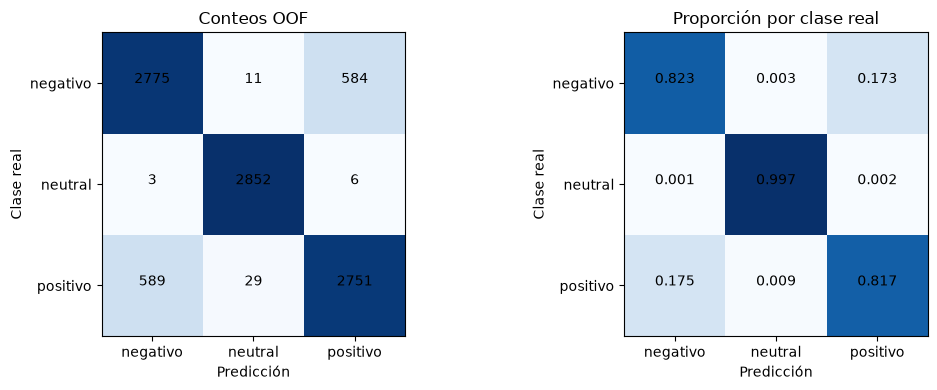

**ID 2518, real positivo, predicción negativo.** Lo compre a mediados de mayo porque necesitaba cambiar el que traia de fabrica. Llego en cuatro dias, bien empacado en una caja de carton normal, nada raro. La relacion calidad-precio quedo confiable en el dia a dia.

**ID 4203, real negativo, predicción positivo.** Después de darle muchas vueltas, me decidí a escribir esto. Me llegó el aparato a mitad de semana, lo pedí un domingo y tardó como cuatro días. La verdad terminé harto de la instalación, me llevó toda la tarde. Por cierto, del botón de encendido no tengo ni una sola queja, se siente bien al presionarlo. Todavía no me decido qué hacer con él.

**ID 442, real negativo, predicción positivo.** Lo pedí un martes por internet y me llegó el jueves a la casa. Voy directo al grano: el sistema de sonido fue un error de compra. La caja pesa como un kilo y pico, eso por si a alguien le sirve de referencia. Por otro lado, no tengo ni una sola queja de la memoria. La uso en la compu del estudio desde hace unas semanas y ahí sigue. Así que ahí lo dejo.

**ID 9924, real negativo, predicción positivo.** Lo pedí un jueves y me llegó al otro día, así que en eso no hubo demora. Lo abrí apenas llegó y me puse a verlo con calma. El peso funciona bastante mal, la verdad, ahí no sé qué le pasa. Lo demás fue aparte: la instalación fue todo un acierto, la hice yo mismo sin ayuda. Cada quien que juzgue.

**ID 5453, real positivo, predicción negativo.** Compre este teclado inalambrico a mediados de año y me llego en tres dias a casa en su caja original. Para ser sincero, el teclado termino siendo inestable para ser honesto, lo he tenido que mover de lugar un par de veces desde que lo arme en el escritorio de la sala. Lo conecte al dispositivo por la noche mientras veia television, sin apuro. Aunque al final la señal luce muy completa al final de cuetas, incluso la probe desde la cocina y no se corto en ningun momento.

In [2]:
a=np.array(r['confusion'])
fig,axs=plt.subplots(1,2,figsize=(11,4))
for ax,v,title in [(axs[0],a,'Conteos OOF'),(axs[1],a/a.sum(axis=1,keepdims=True),'Proporción por clase real')]:
 ax.imshow(v,cmap='Blues');ax.set(xticks=range(3),yticks=range(3),xticklabels=r['labels'],yticklabels=r['labels'],xlabel='Predicción',ylabel='Clase real',title=title)
 for i in range(3):
  for j in range(3):ax.text(j,i,str(v[i,j]) if title=='Conteos OOF' else f'{v[i,j]:.3f}',ha='center')
plt.tight_layout();plt.savefig('reports/confusion_006.png',dpi=160);plt.show()
oof=pd.read_csv('reports/predicciones_oof_006.csv',dtype={'id':str})
train=pd.read_csv('data/train.csv',dtype={'id':str})
e=oof[oof.label.ne(oof.prediction)].merge(train[['id','text']],on='id',validate='one_to_one')
for _,x in e.sample(min(5,len(e)),random_state=42).iterrows():display(Markdown(f'**ID {x.id}, real {x.label}, predicción {x.prediction}.** '+x.text))

Los ejemplos se seleccionan con semilla fija después de cerrar parámetros. No se reentrena para corregirlos individualmente. Las valoraciones contrapuestas no prueban por sí solas la causa de un fallo.

Se conserva el criterio F1 macro y las tres etiquetas explícitas. Precisión, recall y matriz son diagnósticos. Una comparación entre modelos ajustados con matrices OOF previamente generadas sobre todo desarrollo podría filtrar etiquetas al meta-modelo; esta implementación regenera las OOF dentro de cada fit del stacking.

Las capturas no muestran el nombre de la métrica del concurso: el criterio local proviene de la instrucción del usuario. El próximo envío será manual y su resultado sigue pendiente.

In [3]:
display(r.get('checks',{}));display(r.get('artifacts_sha256',{}))
print('Versiones anteriores intactas:',r['old_artifacts_unchanged'])
if r['submission_created']:
 s=pd.read_csv('submissions/submission_006.csv',dtype={'id':str});display(s.head());display(s.answer.value_counts())
else: print(r['reason'])

{'ids_order_schema_labels': True,
 'roundtrip': True,
 'reload_predictions': True,
 'disjoint_groups': True}

{'models/modelo_006.joblib': 'cd89fcb873caee3e91b68155cdad771e0f1a46108e78b70722c0ef28cf487940',
 'submissions/submission_006.csv': '1bba40e5c11065abb60d06f29cbda77c347df4aba14570040d4a340c5324eb4a'}

Versiones anteriores intactas: True


,id,answer
0,0,neutral
1,1,positivo
2,2,neutral
3,3,neutral
4,4,neutral


answer
positivo    1112
negativo    1058
neutral      830
Name: count, dtype: int64